In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [122]:
df = pd.read_csv("train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [123]:
df.shape

(891, 12)

In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [125]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [126]:
df['Survived'].value_counts()

,count
Survived,
0,549
1,342


In [127]:
df['Survived'].value_counts(normalize=True) * 100

,proportion
Survived,
0,61.616162
1,38.383838


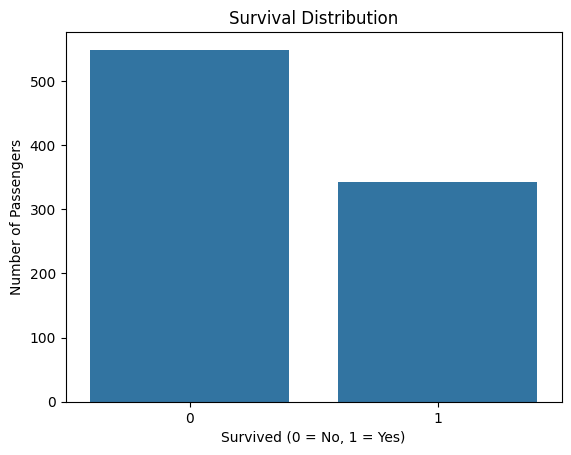

In [128]:
sns.countplot(data=df, x='Survived')

plt.title('Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

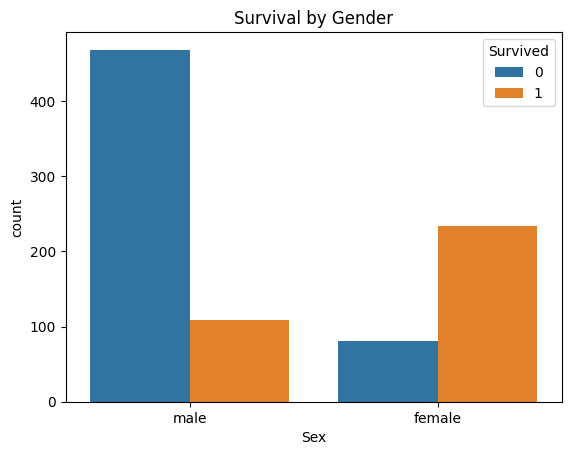

In [129]:
sns.countplot(data=df, x='Sex', hue='Survived')

plt.title('Survival by Gender')
plt.show()

In [130]:
df.groupby('Sex')['Survived'].mean() * 100

,Survived
Sex,
female,74.203822
male,18.890815


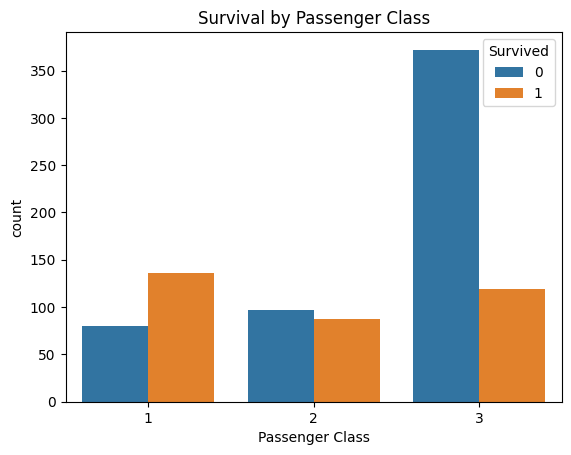

In [131]:
sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title('Survival by Passenger Class')
plt.xlabel('Passenger Class')
plt.show()

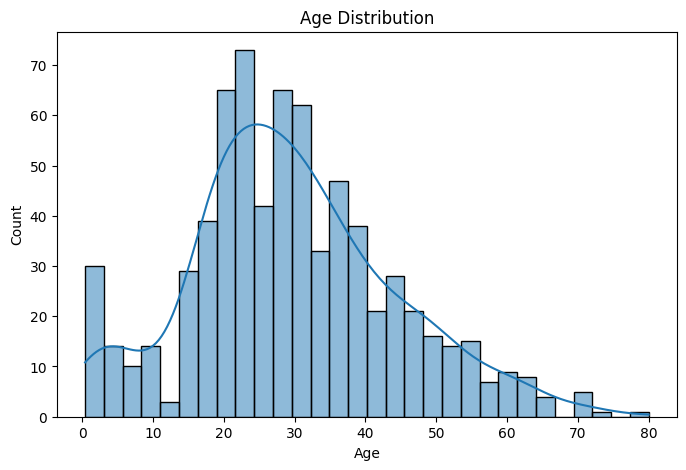

In [132]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title('Age Distribution')
plt.show()

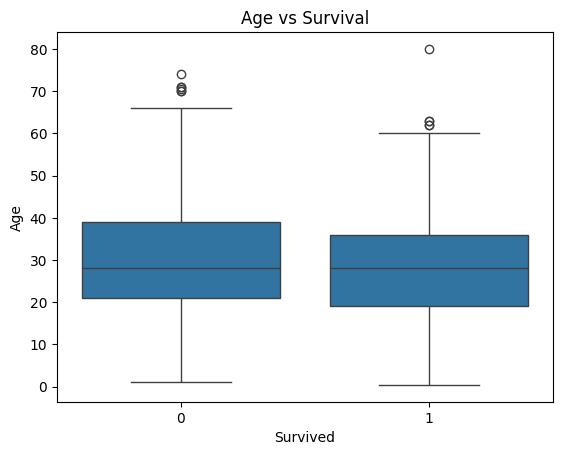

In [133]:
sns.boxplot(data=df, x='Survived', y='Age')

plt.title('Age vs Survival')
plt.show()

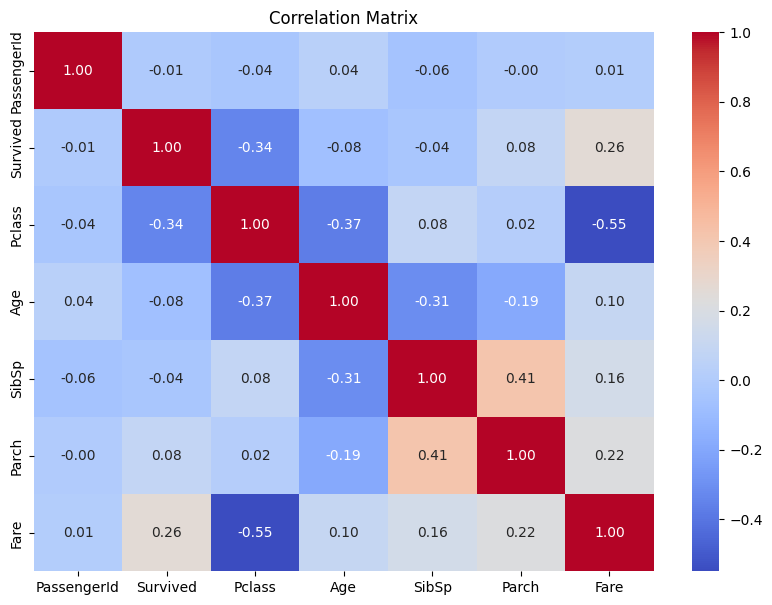

In [134]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [135]:
X = df.drop('Survived', axis=1)

y = df['Survived']

In [136]:
X = X.drop(
    ['PassengerId', 'Name', 'Ticket', 'Cabin'],
    axis=1
)

In [137]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [138]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [139]:
numeric_features = ['Age', 'Fare', 'SibSp', 'Parch']

categorical_features = ['Sex', 'Embarked', 'Pclass']

In [140]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [141]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [142]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [143]:
X_train.shape

(712, 7)

In [144]:
X_test.shape

(179, 7)

In [145]:
y_train.shape

(712,)

In [146]:
y_test.shape

(179,)

In [147]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [148]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Fare', 'SibSp',
                                                   'Parch']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked',
                                                   'Pclass'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [149]:
y_pred_lr = logistic_model.predict(X_test)

In [150]:
print(y_pred_lr[:10])

[0 0 0 0 1 0 1 0 0 0]


In [151]:
print(y_test.values[:10])

[0 0 1 0 1 1 1 0 0 0]


In [152]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(y_test, y_pred_lr)

lr_recall = recall_score(y_test, y_pred_lr)

lr_f1 = f1_score(y_test, y_pred_lr)

In [153]:
print("Logistic Regression Results")
print("---------------------------")

print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

Logistic Regression Results
---------------------------
Accuracy: 0.8044692737430168
Precision: 0.7931034482758621
Recall: 0.6666666666666666
F1 Score: 0.7244094488188977


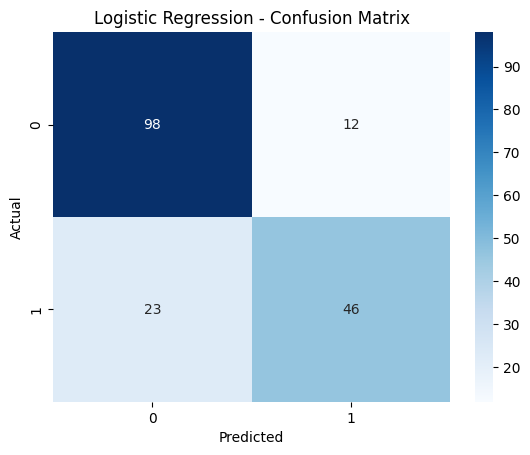

In [154]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [155]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [156]:
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [157]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Fare', 'SibSp',
                                                   'Parch']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked',
                                                   'Pclass'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [158]:
y_pred_rf = random_forest_model.predict(X_test)

In [159]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(y_test, y_pred_rf)

rf_recall = recall_score(y_test, y_pred_rf)

rf_f1 = f1_score(y_test, y_pred_rf)

In [160]:
print("Random Forest Results")
print("---------------------")

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

Random Forest Results
---------------------
Accuracy: 0.8100558659217877
Precision: 0.7868852459016393
Recall: 0.6956521739130435
F1 Score: 0.7384615384615385


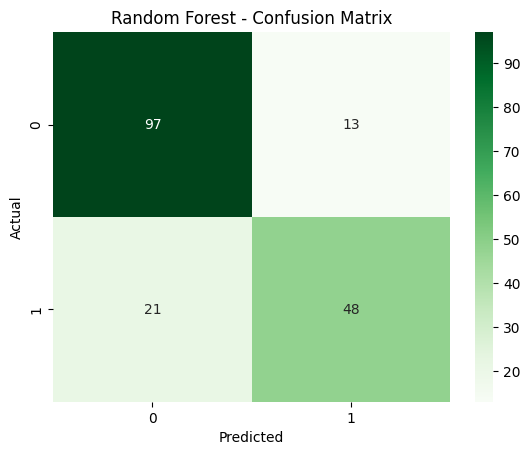

In [161]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [162]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [lr_accuracy, rf_accuracy],
    'Precision': [lr_precision, rf_precision],
    'Recall': [lr_recall, rf_recall],
    'F1 Score': [lr_f1, rf_f1]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.804469,0.793103,0.666667,0.724409
1,Random Forest,0.810056,0.786885,0.695652,0.738462


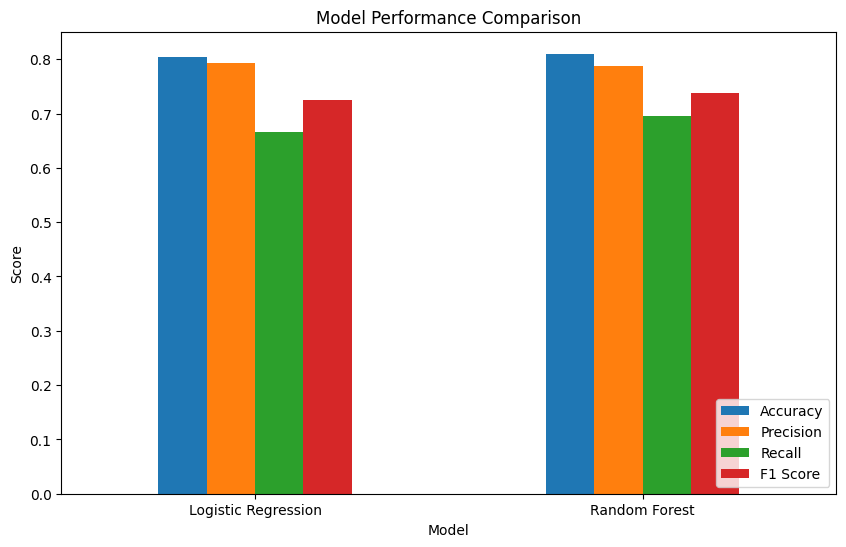

In [163]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')

plt.show()

In [164]:
from sklearn.model_selection import GridSearchCV

In [165]:
lr_params = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs']
}

In [166]:
lr_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=lr_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Age',
                                                                          'Fare',
                                                                          'SibSp',
                                                                          'Parch']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Sex',
                                                                          'Embarked',
                                                                          'Pclass'])])),
                                       ('classifier',
                                        LogisticRegression(max_iter=1000))]),
             n_jobs=-1,
             param_grid={'classifier__C': [0.01, 0.1, 1, 10, 100],
                         'classifier__solver': ['liblinear', 'lbfgs']},
             scoring='f1')

In [167]:
print(lr_grid.best_params_)
print(lr_grid.best_score_)

{'classifier__C': 10, 'classifier__solver': 'liblinear'}
0.7254317003199823


In [168]:
best_lr = lr_grid.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_test)

In [169]:
rf_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 5, 10, 15],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

In [170]:
rf_grid = GridSearchCV(
    estimator=random_forest_model,
    param_grid=rf_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Age',
                                                                          'Fare',
                                                                          'SibSp',
                                                                          'Parch']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Sex',
                                                                          'Embarked',
                                                                          'Pclass'])])),
                                       ('classifier',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [None, 5, 10, 15],
                         'classifier__min_samples_leaf': [1, 2, 4],
                         'classifier__min_samples_split': [2, 5, 10],
                         'classifier__n_estimators': [100, 200, 300]},
             scoring='f1')

In [171]:
print(rf_grid.best_params_)
print(rf_grid.best_score_)

{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
0.7618961007965727


In [172]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

In [173]:
tuned_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Logistic Regression Tuned',
        'Random Forest',
        'Random Forest Tuned'
    ],

    'Accuracy': [
        lr_accuracy,
        accuracy_score(y_test, y_pred_lr_tuned),
        rf_accuracy,
        accuracy_score(y_test, y_pred_rf_tuned)
    ],

    'Precision': [
        lr_precision,
        precision_score(y_test, y_pred_lr_tuned),
        rf_precision,
        precision_score(y_test, y_pred_rf_tuned)
    ],

    'Recall': [
        lr_recall,
        recall_score(y_test, y_pred_lr_tuned),
        rf_recall,
        recall_score(y_test, y_pred_rf_tuned)
    ],

    'F1 Score': [
        lr_f1,
        f1_score(y_test, y_pred_lr_tuned),
        rf_f1,
        f1_score(y_test, y_pred_rf_tuned)
    ]
})

tuned_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.804469,0.793103,0.666667,0.724409
1,Logistic Regression Tuned,0.804469,0.793103,0.666667,0.724409
2,Random Forest,0.810056,0.786885,0.695652,0.738462
3,Random Forest Tuned,0.815642,0.833333,0.652174,0.731707


In [174]:
rf_classifier = best_rf.named_steps['classifier']

feature_names = best_rf.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance

,Feature,Importance
5,cat__Sex_male,0.207446
1,num__Fare,0.199831
4,cat__Sex_female,0.186150
0,num__Age,0.169034
11,cat__Pclass_3,0.068707
2,num__SibSp,0.038188
9,cat__Pclass_1,0.035306
3,num__Parch,0.035073
10,cat__Pclass_2,0.020904
8,cat__Embarked_S,0.020747


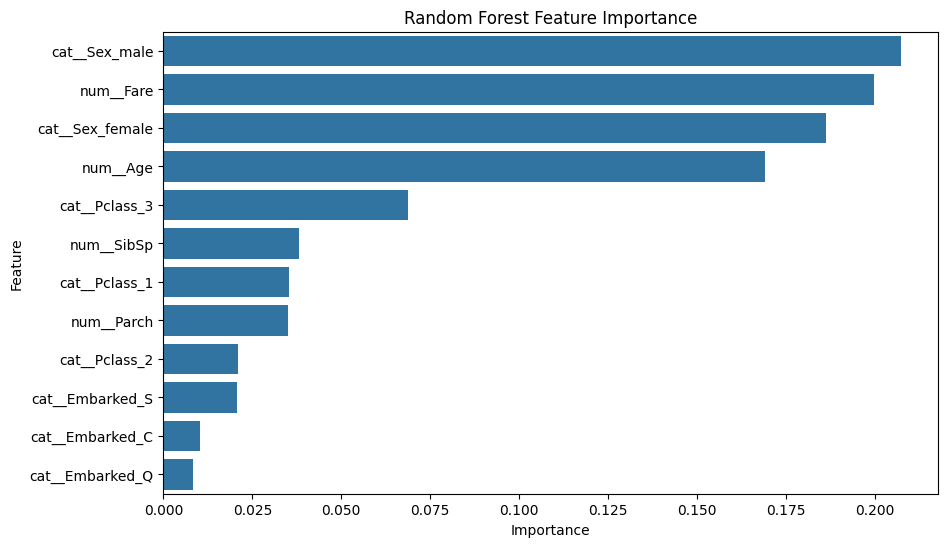

In [175]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.show()

In [176]:
final_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Tuned Logistic Regression',
        'Random Forest',
        'Tuned Random Forest'
    ],

    'Accuracy': [
        lr_accuracy,
        accuracy_score(y_test, y_pred_lr_tuned),
        rf_accuracy,
        accuracy_score(y_test, y_pred_rf_tuned)
    ],

    'Precision': [
        lr_precision,
        precision_score(y_test, y_pred_lr_tuned),
        rf_precision,
        precision_score(y_test, y_pred_rf_tuned)
    ],

    'Recall': [
        lr_recall,
        recall_score(y_test, y_pred_lr_tuned),
        rf_recall,
        recall_score(y_test, y_pred_rf_tuned)
    ],

    'F1 Score': [
        lr_f1,
        f1_score(y_test, y_pred_lr_tuned),
        rf_f1,
        f1_score(y_test, y_pred_rf_tuned)
    ]
})

In [177]:
final_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.804469,0.793103,0.666667,0.724409
1,Tuned Logistic Regression,0.804469,0.793103,0.666667,0.724409
2,Random Forest,0.810056,0.786885,0.695652,0.738462
3,Tuned Random Forest,0.815642,0.833333,0.652174,0.731707


## Conclusion

In this project, we developed and compared two machine learning classification algorithms: Logistic Regression and Random Forest Classifier to predict passenger survival on the Titanic.

After data preprocessing, model training, and evaluation, we obtained the following results:

- Logistic Regression achieved an accuracy of 80.45%.
- Random Forest achieved an accuracy of 81.01%.
- Tuned Random Forest achieved the highest accuracy of 81.56%.
- Random Forest achieved the highest F1-score of 73.85%.

The results show that Random Forest provided the best balance between Precision and Recall among the tested models.

Hyperparameter tuning improved some evaluation metrics but did not improve all metrics simultaneously.

Feature importance analysis also showed that Sex, Fare, and Age were among the most influential features in predicting passenger survival.

Overall, Random Forest performed slightly better than Logistic Regression based on F1-score, while Tuned Random Forest achieved the highest accuracy.

This project demonstrates how different classification algorithms can produce different results depending on their learning mechanisms and evaluation metrics.